In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
!pip install --upgrade --force-reinstall zstandard

In [18]:
df = pd.read_csv("Iris.csv")
df.head()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [14]:
df.drop(columns=['Id'], inplace=True)
df.duplicated().sum()
df['Species'].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

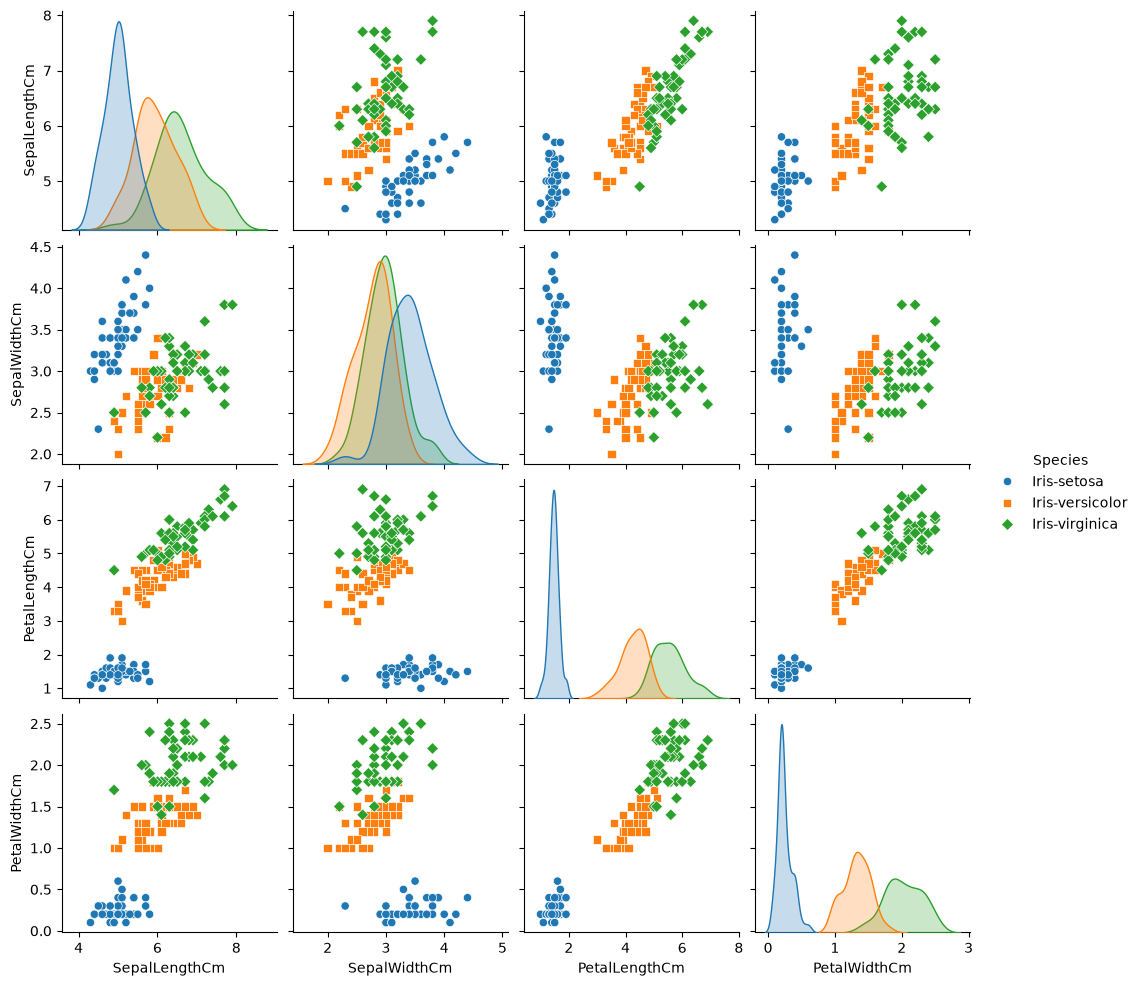

In [15]:
sns.pairplot(df, hue='Species', markers=['o', 's', 'D'])
plt.show()

### Insights from Pairplot
1. **Iris-setosa is completely separate:** It stands out on its own in every plot, especially with smaller petal lengths (1–2 cm) and widths (0.1–0.6 cm). All models should classify it easily.
2. **Petal features matter more than sepals:** Petal length and width separate the species much better than sepal measurements, which overlap a lot.
3. **Slight overlap between versicolor and virginica:** A few points of *versicolor* and *virginica* mix around petal length 4.8–5.0 cm and width 1.6–1.8 cm. Most model errors will likely happen here.
4. **Strong linear trend & normal curves:** Petal length and width move up together in a tight line, and each species forms a rough bell curve—good news for Gaussian Naive Bayes.

In [39]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(drop=None, handle_unknown='ignore', sparse_output=False)
encoded = ohe.fit_transform(df[["Species"]])
encoded_df = pd.DataFrame(encoded, columns=ohe.get_feature_names_out())
df = pd.concat([df.drop(columns=["Species"]), encoded_df], axis=1)

In [41]:
df = df.loc[:, ~df.columns.duplicated()]
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species_0,Species_1,Species_2
0,5.1,3.5,1.4,0.2,1.0,0.0,0.0
1,4.9,3.0,1.4,0.2,1.0,0.0,0.0
2,4.7,3.2,1.3,0.2,1.0,0.0,0.0
3,4.6,3.1,1.5,0.2,1.0,0.0,0.0
4,5.0,3.6,1.4,0.2,1.0,0.0,0.0


# Correlation

In [43]:
num_col = df.select_dtypes(include="number")
corr_matrix = num_col.corr()

In [44]:
corr_matrix

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species_0,Species_1,Species_2
SepalLengthCm,1.000000,-0.109369,0.871754,0.817954,-0.717416,0.079396,0.638020
SepalWidthCm,-0.109369,1.000000,-0.420516,-0.356544,0.595601,-0.464700,-0.130901
PetalLengthCm,0.871754,-0.420516,1.000000,0.962757,-0.922688,0.201587,0.721102
PetalWidthCm,0.817954,-0.356544,0.962757,1.000000,-0.887510,0.118376,0.769134
Species_0,-0.717416,0.595601,-0.922688,-0.887510,1.000000,-0.500000,-0.500000
Species_1,0.079396,-0.464700,0.201587,0.118376,-0.500000,1.000000,-0.500000
Species_2,0.638020,-0.130901,0.721102,0.769134,-0.500000,-0.500000,1.000000


In [48]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species_0,Species_1,Species_2
0,5.1,3.5,1.4,0.2,1.0,0.0,0.0
1,4.9,3.0,1.4,0.2,1.0,0.0,0.0
2,4.7,3.2,1.3,0.2,1.0,0.0,0.0
3,4.6,3.1,1.5,0.2,1.0,0.0,0.0
4,5.0,3.6,1.4,0.2,1.0,0.0,0.0


# Train Test Split - Feature Scaling

In [64]:
# Put the columns to drop inside a list [...]
x = df.drop(["Species_0", "Species_1", "Species_2"], axis=1)

# Combine the 3 target columns into a single column of 0, 1, 2
y = df[["Species_0", "Species_1", "Species_2"]].idxmax(axis=1).str.replace("Species_", "").astype(int)

In [67]:
x.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [71]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [72]:
x_test.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
38,4.4,3.0,1.3,0.2
127,6.1,3.0,4.9,1.8
57,4.9,2.4,3.3,1.0
93,5.0,2.3,3.3,1.0
42,4.4,3.2,1.3,0.2


In [73]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [75]:
x_test_scaled

array([[-1.72156775, -0.0995174 , -1.40385252, -1.32016847],
       [ 0.30848902, -0.0995174 ,  0.64155823,  0.78333648],
       [-1.12449223, -1.45145189, -0.26751321, -0.268416  ],
       [-1.00507713, -1.67677431, -0.26751321, -0.268416  ],
       [-1.72156775,  0.35112743, -1.40385252, -1.32016847],
       [ 0.54731923,  0.57644985,  0.5279243 ,  0.52039836],
       [-1.48273754,  1.25241709, -1.57430342, -1.32016847],
       [-0.52741671,  0.80177226, -1.17658466, -1.32016847],
       [ 0.78614944, -0.0995174 ,  0.81200913,  1.0462746 ],
       [-0.52741671, -0.0995174 ,  0.41429037,  0.3889293 ],
       [ 1.74147027, -0.32483982,  1.43699575,  0.78333648],
       [ 1.26380985,  0.12580502,  0.75519216,  1.44068178],
       [ 0.78614944, -0.0995174 ,  1.15291092,  1.30921272],
       [ 0.66673433,  0.35112743,  0.41429037,  0.3889293 ],
       [-1.00507713,  0.80177226, -1.29021859, -1.32016847],
       [-1.00507713,  0.57644985, -1.34703555, -1.32016847],
       [-0.04975629,  2.

# Train and Evaluate Models

In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, f1_score, precision_score

log_model = LogisticRegression()
log_model.fit(x_train_scaled, y_train)

y_pred = log_model.predict(x_test_scaled)

# Evaluations
print("Logistic Model Predictions")
print("Precision: ", precision_score(y_test, y_pred, average='macro'))
print("Recall Score: ", recall_score(y_test, y_pred, average='macro'))
print("F1 Score: ", f1_score(y_test, y_pred, average='macro'))
print("Accuracy Score: ", accuracy_score(y_test, y_pred))

print("CM:\n", confusion_matrix(y_test, y_pred))


Logistic Model Predictions
Precision:  0.9333333333333332
Recall Score:  0.9333333333333332
F1 Score:  0.9333333333333332
Accuracy Score:  0.9333333333333333
CM:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [86]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, f1_score, precision_score

knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(x_train_scaled, y_train)

y_pred = knn_model.predict(x_test_scaled)

# Evaluations
print("KNN Model Prediction")
print("Precision: ", precision_score(y_test, y_pred, average='macro'))
print("Recall Score: ", recall_score(y_test, y_pred, average='macro'))
print("F1 Score: ", f1_score(y_test, y_pred, average='macro'))
print("Accuracy Score: ", accuracy_score(y_test, y_pred))

print("CM:\n", confusion_matrix(y_test, y_pred))


KNN Model Prediction
Precision:  0.9696969696969697
Recall Score:  0.9666666666666667
F1 Score:  0.9665831244778613
Accuracy Score:  0.9666666666666667
CM:
 [[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


In [88]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, f1_score, precision_score

nb_model = GaussianNB()
nb_model.fit(x_train_scaled, y_train)

y_pred = nb_model.predict(x_test_scaled)

# Evaluations
print("NB Model Prediction")
print("Precision: ", precision_score(y_test, y_pred, average='macro'))
print("Recall Score: ", recall_score(y_test, y_pred, average='macro'))
print("F1 Score: ", f1_score(y_test, y_pred, average='macro'))
print("Accuracy Score: ", accuracy_score(y_test, y_pred))

print("CM:\n", confusion_matrix(y_test, y_pred))


NB Model Prediction
Precision:  0.9696969696969697
Recall Score:  0.9666666666666667
F1 Score:  0.9665831244778612
Accuracy Score:  0.9666666666666667
CM:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


In [89]:
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": log_model,
    "KNN (k=7)": knn_model,
    "Gaussian Naive Bayes": nb_model
}

for name, model in models.items():
    scores = cross_val_score(model, x_train_scaled, y_train, cv=5)
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")


Logistic Regression: 0.9583 (+/- 0.0264)
KNN (k=7): 0.9583 (+/- 0.0373)
Gaussian Naive Bayes: 0.9583 (+/- 0.0264)
